In [1]:
# data manipulation
import numpy as np
import pandas as pd
import datetime as dt
import time
from math import sqrt
from tqdm import tqdm
import holidays

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# feature selection
from sklearn.feature_selection import RFECV

# preprocessing
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# pipeline
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# models
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier

# optimization and hyperparameters
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split

# model evaluation
from sklearn.metrics import confusion_matrix,roc_auc_score,roc_curve,accuracy_score, classification_report,f1_score,precision_score,recall_score

# interpretowalność modelu
import shap
shap.initjs()

# zapisanie modelu
import joblib

# settings
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [2]:
#import io
df = pd.read_excel('file.xls',header=1)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df['EDUCATION'].value_counts()


EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [4]:
df['MARRIAGE'].value_counts()

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In [5]:

df['AGE'].min()

21

In [6]:
df['AGE'].max()

79

In [7]:
df['SEX'].value_counts()

SEX
2    18112
1    11888
Name: count, dtype: int64

In [8]:
df['PAY_0'].value_counts()

PAY_0
 0    14737
-1     5686
 1     3688
-2     2759
 2     2667
 3      322
 4       76
 5       26
 8       19
 6       11
 7        9
Name: count, dtype: int64

In [9]:
df['PAY_2'].value_counts()

PAY_2
 0    15730
-1     6050
 2     3927
-2     3782
 3      326
 4       99
 1       28
 5       25
 7       20
 6       12
 8        1
Name: count, dtype: int64

In [10]:
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [11]:
df1 = df.drop('ID',axis=1)

In [12]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   LIMIT_BAL                   30000 non-null  int64
 1   SEX                         30000 non-null  int64
 2   EDUCATION                   30000 non-null  int64
 3   MARRIAGE                    30000 non-null  int64
 4   AGE                         30000 non-null  int64
 5   PAY_0                       30000 non-null  int64
 6   PAY_2                       30000 non-null  int64
 7   PAY_3                       30000 non-null  int64
 8   PAY_4                       30000 non-null  int64
 9   PAY_5                       30000 non-null  int64
 10  PAY_6                       30000 non-null  int64
 11  BILL_AMT1                   30000 non-null  int64
 12  BILL_AMT2                   30000 non-null  int64
 13  BILL_AMT3                   30000 non-null  int64
 14  BILL_A

# Czyszczenie Danych


## Wykształcenie

In [13]:
df1['EDUCATION'].value_counts()

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [14]:
#0, 5, 6 => 4 jako Other
fil = (df1.EDUCATION == 5) | (df1.EDUCATION == 6) | (df1.EDUCATION == 0)
df1.loc[fil, 'EDUCATION'] = 4
df1.EDUCATION.value_counts()

EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

##  Związek

In [15]:
df1['MARRIAGE'].value_counts()

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In [20]:
# zmiana PAY_0 (nie ma w instrukcji) do PAY_1
df1 = df1.rename(columns={'PAY_0':'PAY_1'})
df1['PAY_1'].value_counts()

PAY_1
 0    14737
-1     5686
 1     3688
-2     2759
 2     2667
 3      322
 4       76
 5       26
 8       19
 6       11
 7        9
Name: count, dtype: int64

In [21]:
# Brak wartosci -2 i -1 => 0
fil = (df1.PAY_1 == -2) | (df1.PAY_1 == -1) | (df1.PAY_1 == 0)
df1.loc[fil, 'PAY_1'] = 0 
fil = (df1.PAY_2 == -2) | (df1.PAY_2 == -1) | (df1.PAY_2 == 0)
df1.loc[fil, 'PAY_2'] = 0
fil = (df1.PAY_3 == -2) | (df1.PAY_3 == -1) | (df1.PAY_3 == 0)
df1.loc[fil, 'PAY_3'] = 0
fil = (df1.PAY_4 == -2) | (df1.PAY_4 == -1) | (df1.PAY_4 == 0)
df1.loc[fil, 'PAY_4'] = 0
fil = (df1.PAY_5 == -2) | (df1.PAY_5 == -1) | (df1.PAY_5 == 0)
df1.loc[fil, 'PAY_5'] = 0
fil = (df1.PAY_6 == -2) | (df1.PAY_6 == -1) | (df1.PAY_6 == 0)
df1.loc[fil, 'PAY_6'] = 0

In [22]:
df1['PAY_1'].value_counts()

PAY_1
0    23182
1     3688
2     2667
3      322
4       76
5       26
8       19
6       11
7        9
Name: count, dtype: int64

In [23]:
df1 = df1.rename(columns={'default payment next month': 'default'})
df1.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default'],
      dtype='object')

In [24]:
# 0 => 3 jako Other
df1.loc[df1.MARRIAGE == 0, 'MARRIAGE'] = 3
summary = df1.MARRIAGE.value_counts()

In [25]:
#Ponieważ klienci, którzy nie zalegali z płatnościami w żadnym miesiącu, nie mogą być potencjalnymi dłużnikami w związku z tym dokonalismy transformacji
fil = (df1.PAY_1 == 0) & (df1.PAY_2 == 0) & (df1.PAY_3 == 0) & (df1.PAY_4 == 0) & (df1.PAY_5 == 0) & (df1.PAY_6 == 0) & (df1.default ==1)
df1.loc[fil,'default'] = 0
#Ponieważ klienci, którzy co miesiąc zalegają z płatnościami, są potencjalnymi dłużnikami, w związku z tym dokonalismy transformacji
fil = (df1.PAY_1 > 0) & (df1.PAY_2 > 0) & (df1.PAY_3 > 0) & (df1.PAY_4 > 0) & (df1.PAY_5 > 0) & (df1.PAY_6 > 0) & (df1.default ==0)
df1.loc[fil,'default'] = 1
df1

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,0,0,0,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,0,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,0,0,0,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,0,0,0,0,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,0,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,0,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [26]:
# Ponieważ ujemna kwota zapłaconego rachunku oznacza, że osoba zapłaciła już należną jej kwotę
fil = (df1.BILL_AMT1 < 0) 
df1.loc[fil,'BILL_AMT1'] = 0

fil = (df1.BILL_AMT2 < 0) 
df1.loc[fil,'BILL_AMT2'] = 0

fil = (df1.BILL_AMT3 < 0) 
df1.loc[fil,'BILL_AMT3'] = 0

fil = (df1.BILL_AMT4 < 0) 
df1.loc[fil,'BILL_AMT4'] = 0

fil = (df1.BILL_AMT5 < 0) 
df1.loc[fil,'BILL_AMT5'] = 0

fil = (df1.BILL_AMT6 < 0) 
df1.loc[fil,'BILL_AMT6'] = 0

In [27]:
# nie mamy wartosc zerowych - dobrze
df1.isnull().sum()

LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64

In [28]:
X = df1.drop('default',axis=1)
Y = df1['default']
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2


#apply SelectKBest class to extract top 10 best features
bestfeatures = SelectKBest(score_func=chi2, k=23)
fit = bestfeatures.fit(X,Y)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(X.columns)

#concat two dataframes for better visualization
featureScores = pd.concat([dfcolumns,dfscores],axis=1)
featureScores.columns = ['Specs','Score']  #naming the dataframe columns
print(featureScores.nlargest(20,'Score'))

        Specs         Score
0   LIMIT_BAL  1.057492e+08
18   PAY_AMT2  9.582460e+06
17   PAY_AMT1  8.290986e+06
22   PAY_AMT6  6.986573e+06
20   PAY_AMT4  6.067629e+06
19   PAY_AMT3  6.039725e+06
21   PAY_AMT5  5.947016e+06
16  BILL_AMT6  2.106857e+06
15  BILL_AMT5  1.726431e+06
11  BILL_AMT1  9.045943e+05
14  BILL_AMT4  5.777365e+05
12  BILL_AMT2  8.573634e+04
5       PAY_1  1.890309e+04
6       PAY_2  1.848116e+04
7       PAY_3  1.588063e+04
8       PAY_4  1.584077e+04
9       PAY_5  1.580411e+04
10      PAY_6  1.393191e+04
13  BILL_AMT3  1.922741e+02
2   EDUCATION  1.476439e+01


In [30]:
df1[["LIMIT_BAL","AGE"]].describe()

,LIMIT_BAL,AGE
count,30000.000000,30000.000000
mean,167484.322667,35.485500
std,129747.661567,9.217904
min,10000.000000,21.000000
25%,50000.000000,28.000000
50%,140000.000000,34.000000
75%,240000.000000,41.000000
max,1000000.000000,79.000000


## Feature Engineering


In [31]:
categorical = ['SEX', 'EDUCATION', 'MARRIAGE','PAY_1', 'PAY_2','PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
numerical = ['LIMIT_BAL','AGE' ,'BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1','PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

 Box Plot of LIMIT_BAL


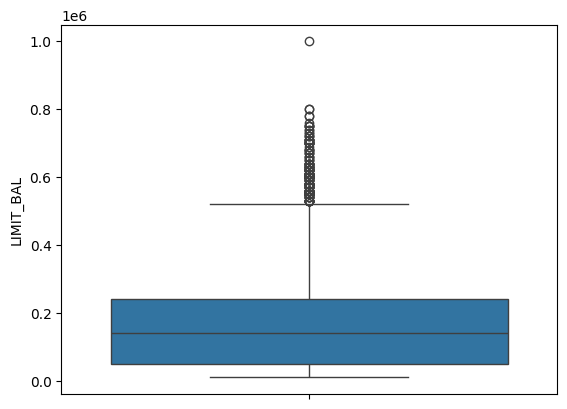

 Box Plot of AGE


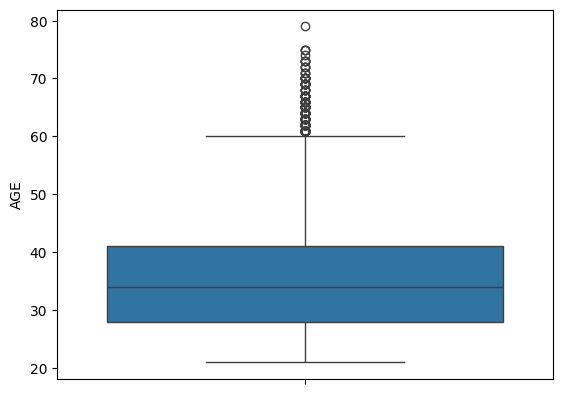

 Box Plot of BILL_AMT1


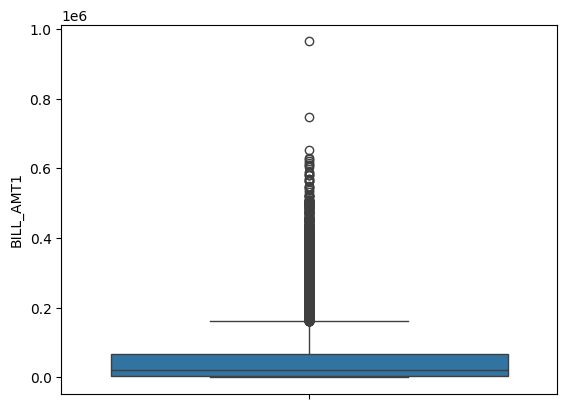

 Box Plot of BILL_AMT2


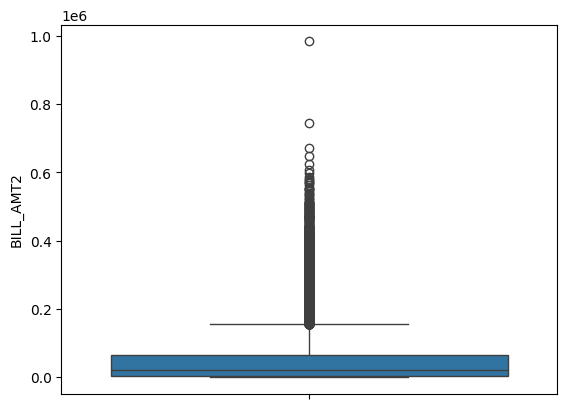

 Box Plot of BILL_AMT3


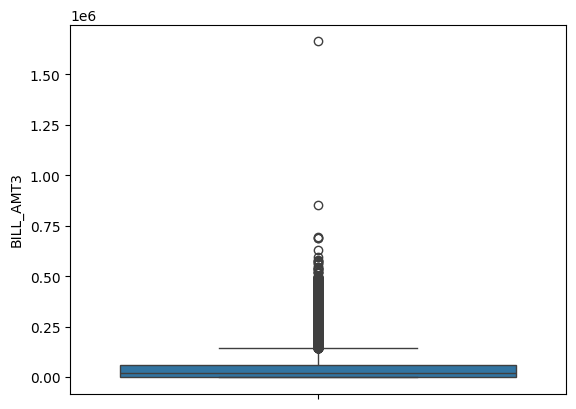

 Box Plot of BILL_AMT4


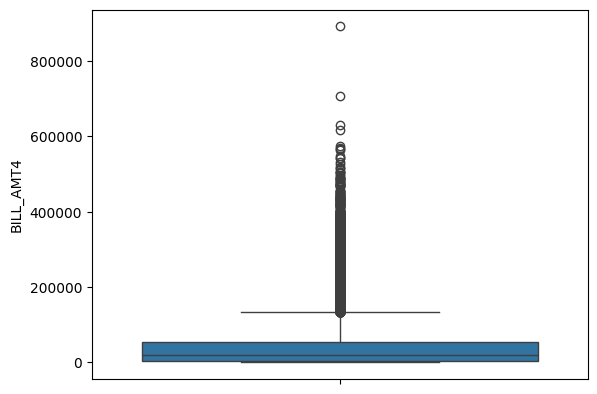

 Box Plot of BILL_AMT5


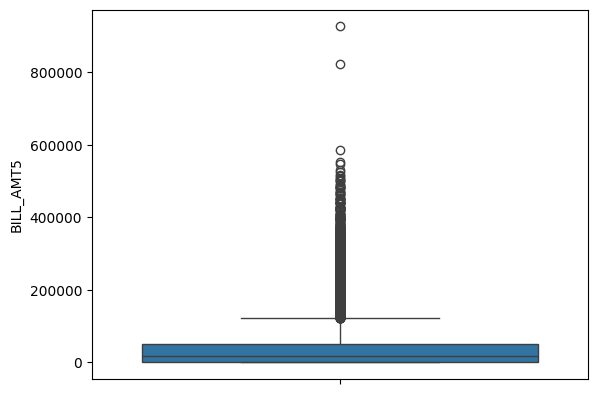

 Box Plot of BILL_AMT6


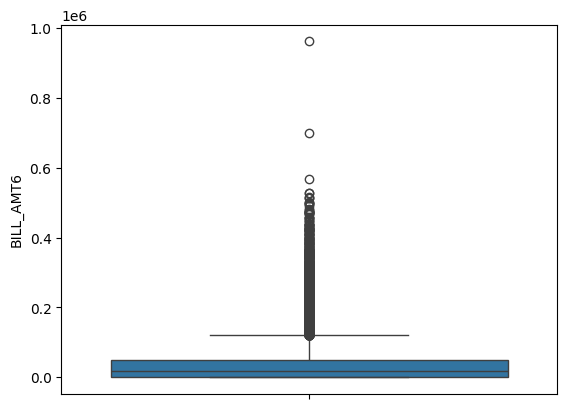

 Box Plot of PAY_AMT1


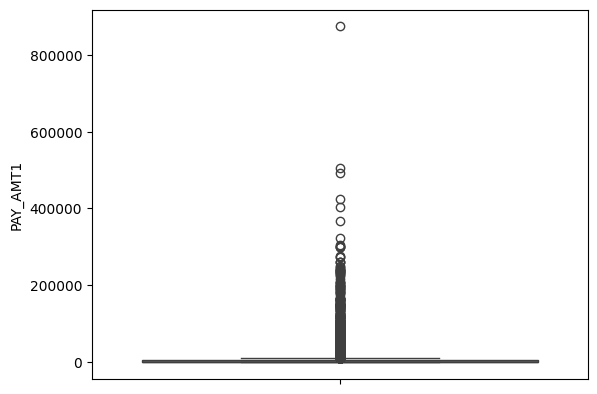

 Box Plot of PAY_AMT2


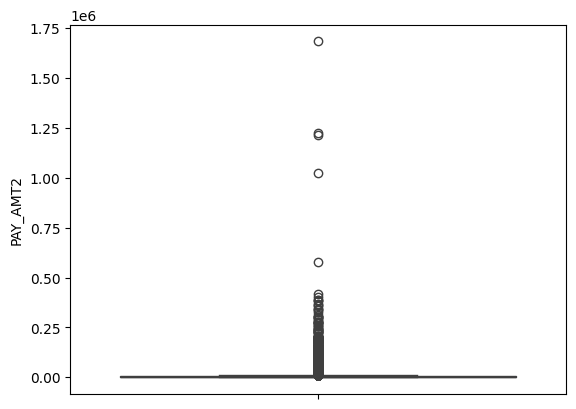

 Box Plot of PAY_AMT3


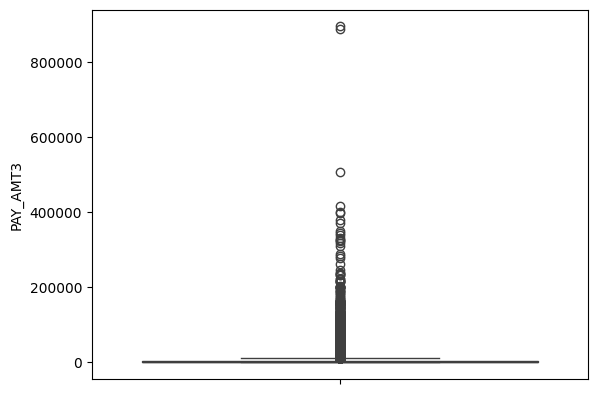

 Box Plot of PAY_AMT4


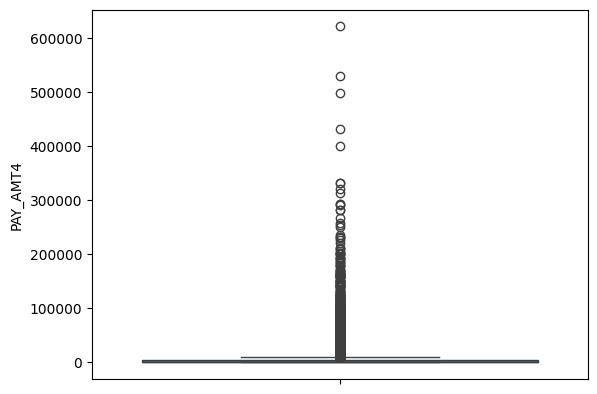

 Box Plot of PAY_AMT5


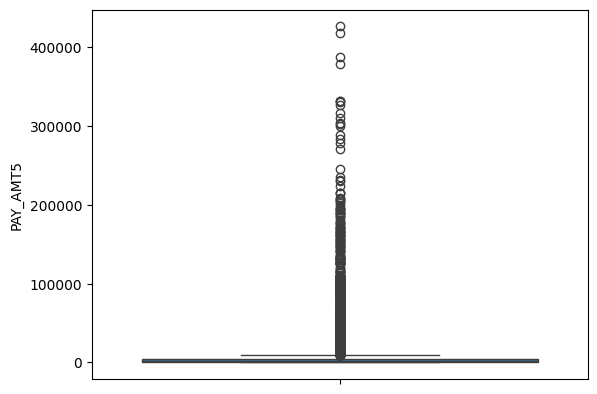

 Box Plot of PAY_AMT6


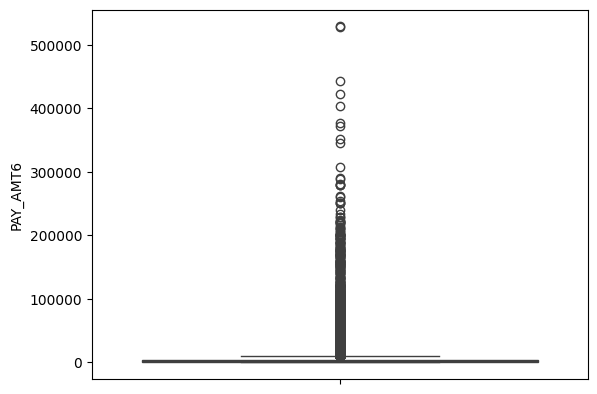

In [32]:
for cols in numerical:
    sns.boxplot(df1[cols])
    print(' Box Plot of',cols)
    plt.show()

In [199]:
print("Liczba rekordów wartości odstających");print()
for i in df1[numerical]:
    u = df1[i].quantile(0.75) + 1.5*(df1[i].quantile(0.75)-df1[i].quantile(0.25))
    print(i , " : " , df1[df1[i] > u][i].count())

Liczba rekordów wartości odstających

LIMIT_BAL  :  167
AGE  :  272
BILL_AMT1  :  2398
BILL_AMT2  :  2395
BILL_AMT3  :  2468
BILL_AMT4  :  2620
BILL_AMT5  :  2724
BILL_AMT6  :  2688
PAY_AMT1  :  2745
PAY_AMT2  :  2714
PAY_AMT3  :  2598
PAY_AMT4  :  2994
PAY_AMT5  :  2945
PAY_AMT6  :  2958


## Standaryzacja

In [33]:
SS = StandardScaler()
df1[numerical] = pd.DataFrame(SS.fit_transform(df1[numerical]))

## Podział 

In [34]:
x = df1.drop('default',axis=1)
y = df1['default']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)


from imblearn.over_sampling import SMOTE
smt = SMOTE(random_state=33)
x_train_new, y_train_new = smt.fit_resample(x_train, y_train.ravel())

## KNN Model

In [35]:
knn = KNeighborsClassifier()
knn.fit(x_train_new,y_train_new)
knn_train_score = knn.score(x_train_new,y_train_new)
print('Training Accuracy Score : ',knn_train_score)

Training Accuracy Score :  0.9416021256147888


In [36]:
y_pred_knn = knn.predict(x_test)
knn_test_score = accuracy_score(y_test,y_pred_knn)
print('Testing Accuracy Score',knn_test_score)

Testing Accuracy Score 0.8618888888888889


In [37]:
cm = confusion_matrix(y_test,y_pred_knn)
cm

array([[6581, 1030],
       [ 213, 1176]])

In [38]:
knn_f1_score = f1_score(y_test,y_pred_knn)
print(knn_f1_score)

0.6542420027816411


In [39]:
knn_recall_score = recall_score(y_test,y_pred_knn)
print(knn_recall_score)

0.8466522678185745


In [40]:
knn_precision_score = precision_score(y_test,y_pred_knn)
print(knn_precision_score)

0.5330915684496826


<Axes: >

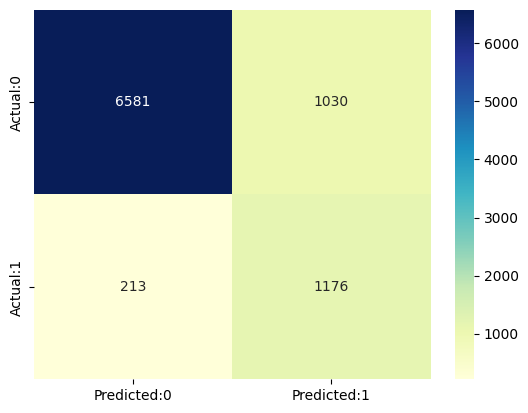

In [41]:
cm = pd.DataFrame(data=cm,columns=['Predicted:0','Predicted:1'],index=['Actual:0','Actual:1'])
sns.heatmap(cm,annot=True,fmt ='d',cmap='YlGnBu')

In [42]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.86      0.91      7611
           1       0.53      0.85      0.65      1389

    accuracy                           0.86      9000
   macro avg       0.75      0.86      0.78      9000
weighted avg       0.90      0.86      0.87      9000



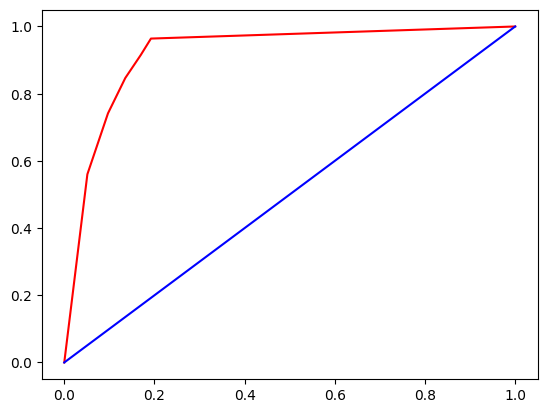

In [43]:
y_prob = knn.predict_proba(x_test)[:,1]
fpr,tpr,threshold = roc_curve(y_test,y_prob)
plt.plot(fpr,tpr,color='r')
plt.plot(fpr,fpr,color='b')

In [238]:
knn_roc = roc_auc_score(y_test,y_prob)

## Random Forest 

In [221]:
rfc = RandomForestClassifier()
rfc.fit(x_train_new,y_train_new)
rf_train_score = rfc.score(x_train_new,y_train_new)
print('Training Accuracy Score : ',rf_train_score)

Training Accuracy Score :  0.9997738707671434


In [222]:
y_pred_rf = rfc.predict(x_test)
rf_test_score = accuracy_score(y_test,y_pred_rf)
print('Testing Accuracy Score : ',rf_test_score)

Testing Accuracy Score :  0.8836666666666667


In [223]:
cm = confusion_matrix(y_test,y_pred_rf)
cm

array([[6854,  757],
       [ 290, 1099]])

<Axes: >

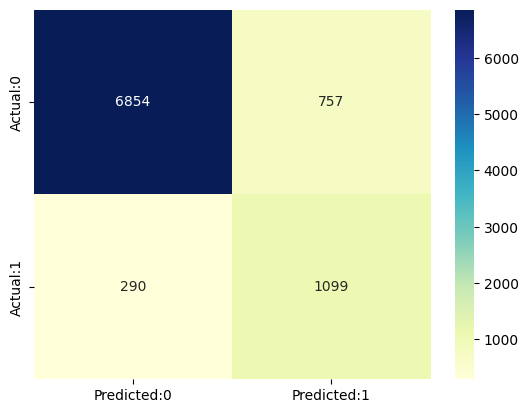

In [225]:
cm = pd.DataFrame(data=cm,columns=['Predicted:0','Predicted:1'],index=['Actual:0','Actual:1'])
sns.heatmap(cm,annot=True,fmt ='d',cmap='YlGnBu')

In [226]:
rf_f1_score = f1_score(y_test,y_pred_rf)
print(rf_f1_score)

0.6773497688751926


In [227]:
rf_recall_score = recall_score(y_test,y_pred_rf)
print(rf_recall_score)

0.7912167026637869


In [228]:
rf_precision_score = precision_score(y_test,y_pred_rf)
print(rf_precision_score)

0.5921336206896551


In [229]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.96      0.90      0.93      7611
           1       0.59      0.79      0.68      1389

    accuracy                           0.88      9000
   macro avg       0.78      0.85      0.80      9000
weighted avg       0.90      0.88      0.89      9000



In [231]:
y_prob = rfc.predict_proba(x_test)[:,1]
y_prob

array([0.  , 0.01, 0.  , ..., 0.  , 0.  , 0.  ])

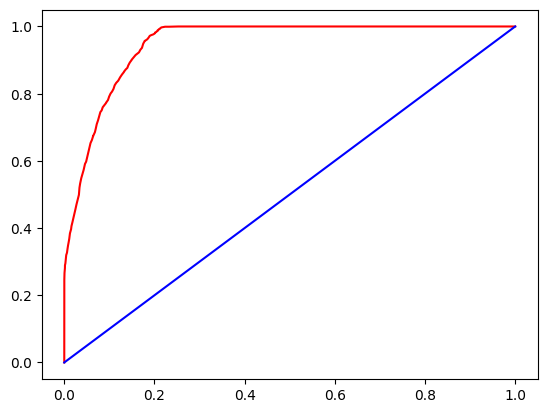

In [233]:
fpr,tpr,threshold = roc_curve(y_test,y_prob)
plt.plot(fpr,tpr,color='r')
plt.plot(fpr,fpr,color='b')

In [234]:
rf_roc = roc_auc_score(y_test,y_prob)
print(rf_roc)

0.9479463006774989


In [239]:
model = {
    'Train Accuracy' : [knn_train_score,rf_train_score],
    'Test Accuracy' : [knn_test_score,rf_test_score],
    'F1 Score' : [knn_f1_score,rf_f1_score,],
    'Recall Score' : [knn_recall_score,rf_recall_score],
    'Precision Score' : [knn_precision_score,rf_precision_score],
    'Roc Auc Score' : [knn_roc,rf_roc]
}
    
result_all_models = pd.DataFrame(model,index=['K Nearest Neighbor Model','Random Forest Model']) 
result_all_models

,Train Accuracy,Test Accuracy,F1 Score,Recall Score,Precision Score,Roc Auc Score
K Nearest Neighbor Model,0.941687,0.861444,0.653515,0.846652,0.532127,0.947946
Random Forest Model,0.999774,0.883667,0.677350,0.791217,0.592134,0.947946
